# The Ultimate OpenCV 7-Day Bootcamp: Professional Mastery
Welcome to the comprehensive, professional-grade OpenCV training notebook for Team Chati Pati.
This resource is designed to transition you from a beginner to a computer vision professional ready for the final round of the Quera Image Processing Olympiad.

**Roadmap Overview:**
* **Day 1:** Image Processing Basics, Color Spaces, ROI, Histograms, Pixel Manipulation
* **Day 2:** Filtering & Thresholding, Noise Mitigation
* **Day 3:** Edge Detection, Gradients, Auto-Canny
* **Day 4:** Morphology, Contours, Connected Components
* **Day 5:** Hough Lines, Robust Geometry Algorithms
* **Day 6:** Perspective Transform, Synthetic Datasets, Evaluation Metrics
* **Day 7:** Phase 1 Project (End-to-End Expert Pipeline)

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import random

plt.rcParams['figure.figsize'] = (10, 6)

def show_image(img, title="Image", cmap=None):
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Day 1 — Image Processing Basics & Expert Techniques
**Topics:** BGR / RGB, HSV, Grayscale, Resize, Crop / ROI, Histogram, Pixel manipulation

### 1. Image Sourcing & 5+ Reusable Core Functions
OpenCV reads color in **BGR** format, while libraries like Matplotlib expect **RGB**. 
* **HSV** (Hue, Saturation, Value) decouples color from lighting, crucial for robust segmentation.
* **Histograms** show pixel intensity distributions.
* **Resizing** with `cv2.INTER_AREA` is best for downsampling.

### Understanding the Core Utility Functions

Before diving into advanced processing, we establish a set of robust utility functions to handle repetitive tasks cleanly and efficiently:

**1. Safe Image Loading (`load_image`)**
* OpenCV's `cv2.imread` fails silently (returns `None`) if a file path is incorrect, which can cause cryptic downstream errors. This function adds explicit error handling.
* It automatically converts the color space from BGR (OpenCV's default) to RGB (Matplotlib's standard) so images render with their true colors during visualization.

**2. Aspect-Aware Resizing (`resize_keep_ratio`)**
* Forcing an image into a fixed square resolution distorts geometric features. This function calculates the aspect ratio dynamically based on a single target dimension (width or height).
* It applies `cv2.INTER_AREA`, which is mathematically the most accurate interpolation method for downsampling images without introducing moiré patterns or jagged edges.

**3. Region of Interest (`extract_roi`)**
* Since OpenCV images are natively parsed as NumPy arrays, we can crop them instantly and efficiently using standard matrix slicing operations: `image[y_start:y_end, x_start:x_end]`.

**4. Grid Visualization (`show_images_grid`)**
* A Matplotlib wrapper designed to plot arrays of images in a clean, comparative grid format. It handles axis flattening and layout adjustments (`tight_layout`) automatically, keeping our primary algorithmic pipeline code clean and readable.

In [4]:
# Reusable Function 2: Load Image safely
def load_image(filepath, as_rgb=True):
    '''Loads an image safely. Converts to RGB by default.'''
    img = cv2.imread(filepath)
    if img is None: raise ValueError(f"Not found: {filepath}")
    if as_rgb: img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

# Reusable Function 3: Resize keeping aspect ratio
def resize_keep_ratio(img, target_width=None, target_height=None):
    '''Resizes an image while preserving the aspect ratio.'''
    h, w = img.shape[:2]
    if target_width: 
        ratio = target_width / w
        dim = (target_width, int(h * ratio))
    else: 
        ratio = target_height / h
        dim = (int(w * ratio), target_height)
    return cv2.resize(img, dim, interpolation=cv2.INTER_AREA)

# Reusable Function 4: Extract Region of Interest (ROI)
def extract_roi(img, x, y, w, h):
    '''Extracts a sub-region from an image using Numpy slicing.'''
    return img[y:y+h, x:x+w]

# Reusable Function 5: Display multiple images
def show_images_grid(images, titles, rows, cols, figsize=(15, 10), cmap=None):
    '''Displays a list of images in a grid format.'''
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows * cols == 1: axes = np.array([axes])
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = axes.flatten()[i]
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 2. Practice: Pixel Manipulation, Color Spaces & Histograms
Here we manipulate pixels, extract an ROI, compare RGB/BGR/HSV, and analyze color histograms.

### Understanding Pixel Manipulation, Color Spaces, and Histograms

This section explores foundational operations in computer vision that involve directly interacting with image arrays and analyzing their statistical color properties.

**1. Pixel Manipulation & ROI**
* **Direct Access:** Since OpenCV treats images as multi-dimensional NumPy arrays, we can modify specific regions by directly assigning new color values to array slices (e.g., setting a 50x50 block to `[255, 0, 0]` creates a pure red square).
* **Region of Interest (ROI):** Cropping specific functional areas (like the soccer ball) allows algorithms to focus processing power only on relevant parts of an image, discarding background noise.

**2. Color Space Conversions (`cv2.cvtColor`)**
* **RGB vs. BGR:** OpenCV inherently processes images in BGR format, while visualization libraries like Matplotlib expect RGB. If we pass a BGR image to Matplotlib without converting it back, the red and blue channels are swapped, making the image look unnatural.
* **HSV (Hue, Saturation, Value):** This color space separates pure color information (Hue) from lighting intensity (Value). This decoupling makes HSV significantly more robust for color-based object tracking and segmentation compared to RGB, which is highly sensitive to shadows and highlights.

**3. Image Histograms (`cv2.calcHist`)**
* **Concept:** A histogram is a graphical representation of the tonal distribution in a digital image. It plots the exact number of pixels that exist for each tonal value (from 0 to 255).
* **Mechanism:** We iterate through the R, G, and B channels and use `cv2.calcHist` to compute the frequency of each pixel intensity. Analyzing these curves is critical for understanding the exposure, contrast, and color balance of an image, which guides subsequent filtering and thresholding decisions.

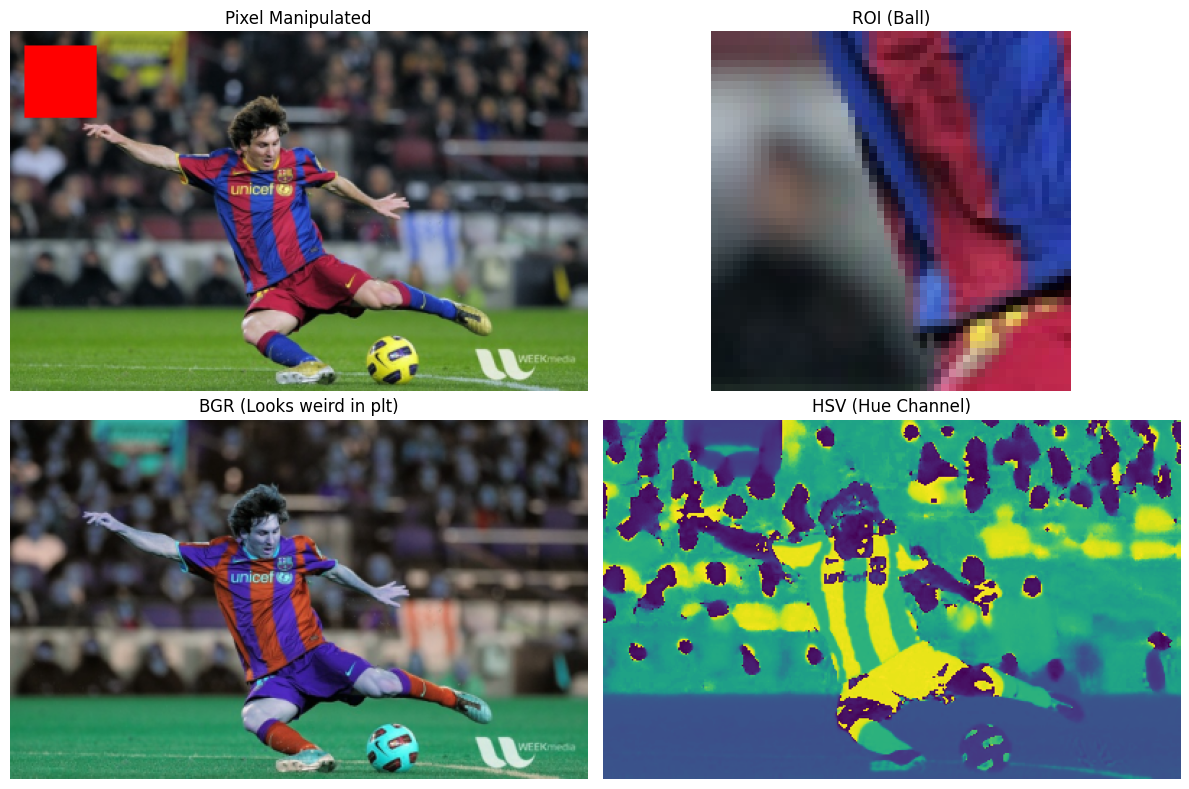

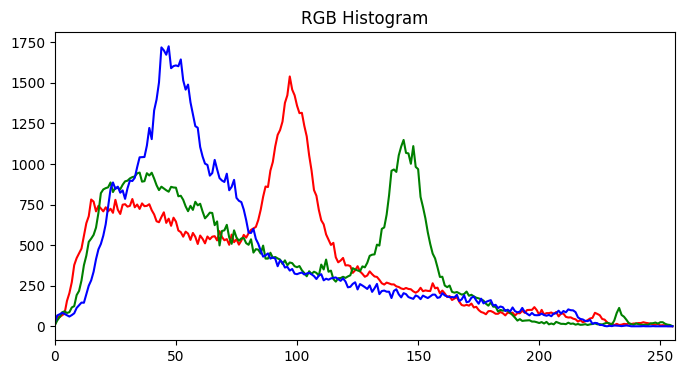

In [4]:
# Load Messi image and resize
img_messi = load_image('data/images/messi.jpg')
img_resized = resize_keep_ratio(img_messi, target_width=400)

# Pixel Manipulation: Draw a red square by directly modifying pixel values
img_pixel = img_resized.copy()
img_pixel[10:60, 10:60] = [255, 0, 0] # RGB Red

# Extract ROI (The soccer ball)
roi_ball = extract_roi(img_resized, x=135, y=140, w=50, h=50)

# Color Space Conversions
img_bgr = cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR)
img_hsv = cv2.cvtColor(img_resized, cv2.COLOR_RGB2HSV)

show_images_grid(
    [img_pixel, roi_ball, img_bgr, img_hsv[..., 0]], 
    ['Pixel Manipulated', 'ROI (Ball)', 'BGR (Looks weird in plt)', 'HSV (Hue Channel)'], 
    2, 2, figsize=(12, 8)
)

# Histogram Comparison
def plot_histograms(img_rgb):
    '''Generates and plots histograms for R, G, B channels.'''
    colors = ('r', 'g', 'b')
    plt.figure(figsize=(8, 4))
    for i, color in enumerate(colors):
        hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        plt.plot(hist, color=color)
        plt.xlim([0, 256])
    plt.title('RGB Histogram')
    plt.show()

plot_histograms(img_resized)

## Day 2 — Filtering & Thresholding
**Topics:** Gaussian Blur, Median Blur, Bilateral Filter, Otsu Threshold, Adaptive Threshold

### 1. Noise Generation & Filtering
* **Gaussian Blur:** Best for Gaussian/normal sensor noise.
* **Median Blur:** Non-linear filter. Best for Salt & Pepper noise.
* **Bilateral Filter:** Edge-preserving blur.

### Understanding Noise Generation Functions

In real-world computer vision applications, images are rarely perfect. They suffer from various types of artifacts due to sensor limitations, low lighting, or transmission errors. To build robust preprocessing pipelines, we simulate these conditions using two common noise models:

**1. Gaussian Noise (`add_gaussian_noise`)**
* **Concept:** Models statistical noise arising from sensor heat or low-light conditions. It alters every pixel in the image by adding a random value drawn from a Gaussian (Normal) distribution.
* **Mechanism:** We generate a noise matrix using `np.random.normal` based on a specified `mean` and standard deviation (`std`). The image and noise are temporarily cast to `float32` to prevent overflow during addition. Finally, `np.clip` ensures the pixel values remain strictly within the valid `[0, 255]` 8-bit range before converting back to `uint8`.

**2. Salt-and-Pepper Noise (`add_sp_noise`)**
* **Concept:** Models impulse noise caused by dead pixels, analog-to-digital converter errors, or bit transmission errors. Instead of altering all pixels slightly, it corrupts a specific percentage of pixels, turning them completely white ("salt") or completely black ("pepper").
* **Mechanism:** Based on the probability parameter (`prob`), the function calculates the exact number of pixels to corrupt. It randomly selects pixel coordinates across the image's height and width, assigning `255` to the "salt" coordinates and `0` to the "pepper" coordinates.

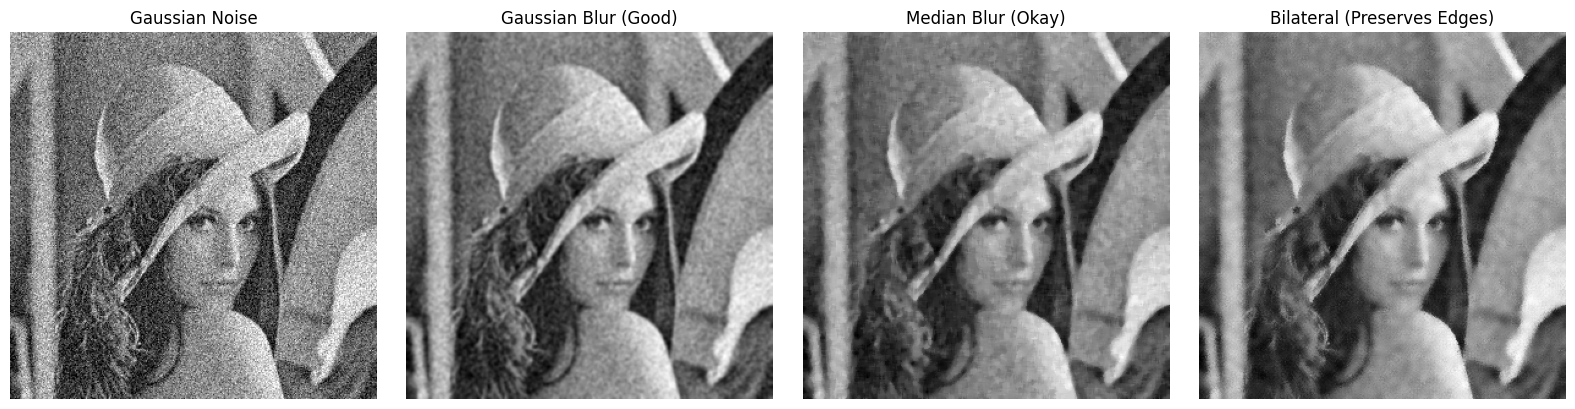

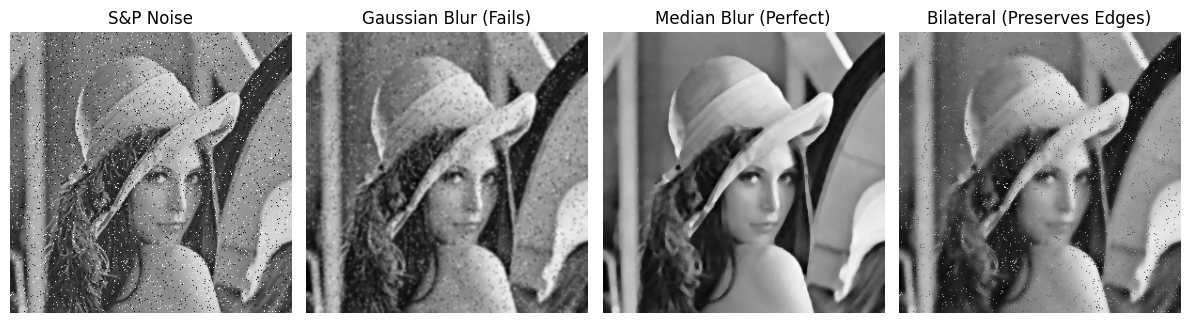

In [10]:
def add_gaussian_noise(image, mean=0, std=25):
    noise = np.random.normal(mean, std, image.shape).astype(np.float32)
    noisy = cv2.add(image.astype(np.float32), noise)
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_sp_noise(image, prob=0.05):
    noisy = np.copy(image)
    num_salt = np.ceil(prob * image.size * 0.5)
    num_pepper = np.ceil(prob * image.size * 0.5)
    
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 255
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 0
    return noisy

img_lena = cv2.cvtColor(load_image('data/images/lena.jpg'), cv2.COLOR_RGB2GRAY)
img_lena = resize_keep_ratio(img_lena, target_width=300)

img_gauss_noise = add_gaussian_noise(img_lena, std=30)
img_sp_noise = add_sp_noise(img_lena, prob=0.05)

# Visual Comparison Report (Evaluation)
gauss_on_gauss = cv2.GaussianBlur(img_gauss_noise, (5, 5), 0)
median_on_gauss = cv2.medianBlur(img_gauss_noise, 5)
bilateral_on_gauss = cv2.bilateralFilter(img_gauss_noise, 9, 75, 75)

gauss_on_sp = cv2.GaussianBlur(img_sp_noise, (5, 5), 0)
median_on_sp = cv2.medianBlur(img_sp_noise, 5)
bilateral_on_sp = cv2.bilateralFilter(img_sp_noise,9,75,75)

show_images_grid(
    [img_gauss_noise, gauss_on_gauss, median_on_gauss, bilateral_on_gauss],
    ['Gaussian Noise', 'Gaussian Blur (Good)', 'Median Blur (Okay)', 'Bilateral (Preserves Edges)'],
    1, 4, cmap='gray', figsize=(16, 4)
)

show_images_grid(
    [img_sp_noise, gauss_on_sp, median_on_sp, bilateral_on_sp],
    ['S&P Noise', 'Gaussian Blur (Fails)', 'Median Blur (Perfect)', 'Bilateral (Preserves Edges)'],
    1, 4, cmap='gray', figsize=(12, 4)
)

### 2. Thresholding
Converting grayscale to binary using Otsu and Adaptive techniques.

### Understanding Thresholding Techniques

Thresholding is the process of converting a grayscale image into a binary (black-and-white) image. It is a crucial preprocessing step for tasks like OCR, edge detection, and contour extraction. Here we compare two fundamentally different approaches:

**1. Global Thresholding with Otsu's Method**
* **Concept:** Assumes the image histogram is bimodal (contains two distinct peaks: foreground and background). It automatically calculates a single, optimal global threshold value that minimizes the intra-class variance between these two peaks.
* **Mechanism:** `cv2.threshold` returns two values: the calculated threshold and the processed image. By passing `cv2.THRESH_OTSU`, the hardcoded threshold (e.g., `0`) is ignored.
* **Limitation:** It fails spectacularly if the image has uneven illumination or shadows, as a single global value cannot cleanly separate foreground from background across varying lighting conditions.

**2. Adaptive Thresholding (`cv2.adaptiveThreshold`)**
* **Concept:** Calculates the threshold dynamically for small, localized regions of the image rather than using a single global value.
* **Mechanism:** 
  * `cv2.ADAPTIVE_THRESH_GAUSSIAN_C`: The threshold value is a Gaussian-weighted sum of the neighborhood pixels.
  * `Block Size (11)`: Determines the size of the neighborhood area (11x11 pixels) used to calculate the local threshold.
  * `Constant C (2)`: A constant value subtracted from the calculated mean or weighted mean to fine-tune the thresholding and reduce background noise.
* **Advantage:** Highly robust against varying lighting conditions, gradients, and shadows, making it ideal for real-world document scanning and object segmentation.

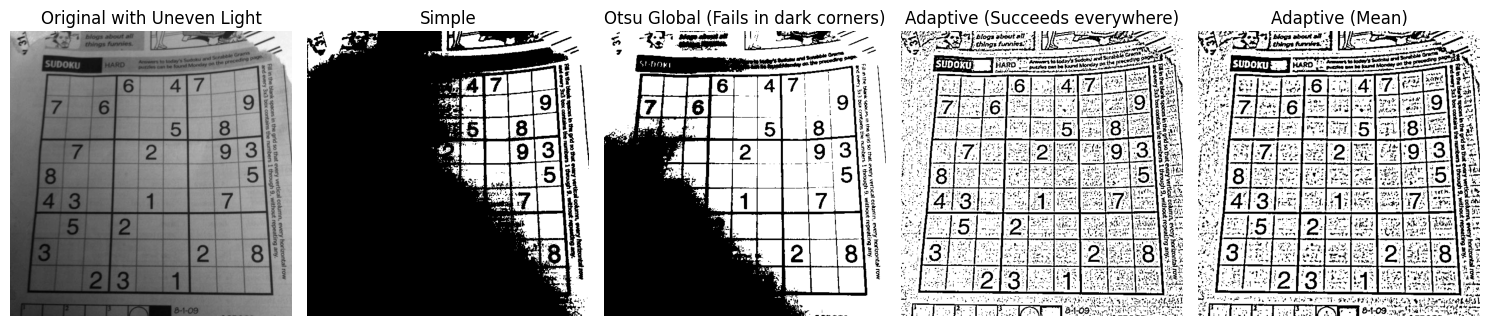

In [ ]:
img_sudoku = cv2.cvtColor(load_image('data/images/sudoku.png'), cv2.COLOR_RGB2GRAY)
_ ,th_simple = cv2.threshold(img_sudoku,127,255,cv2.THRESH_BINARY)
_, th_otsu = cv2.threshold(img_sudoku, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
th_adaptive = cv2.adaptiveThreshold(img_sudoku, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)
th_adaptive_mean = cv2.adaptiveThreshold(img_sudoku,255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,11,2)

show_images_grid(
    [img_sudoku, th_simple, th_otsu, th_adaptive, th_adaptive_mean],
    ['Original with Uneven Light', 'Simple' ,"Otsu Global (Fails in dark corners)", 'Adaptive (Succeeds everywhere)', 'Adaptive (Mean)'],
    1, 5, cmap='gray', figsize=(15, 5)
)

## Day 3 — Edge Detection
**Topics:** Sobel, Scharr, Laplacian, Canny

### Understanding Gradients and Edge Detection

Edge detection fundamentally relies on calculating image gradients, which measure the directional change in pixel intensity. 

**1. Sobel Operator (`cv2.Sobel`)**
* **Concept:** Calculates the first spatial derivative of the image. 
  * `Sobel X` (order `dx=1, dy=0`) highlights vertical edges.
  * `Sobel Y` (order `dx=0, dy=1`) highlights horizontal edges.
* **The `CV_64F` Trick:** When transitioning from white to black, the gradient is negative. If we set the output depth to standard 8-bit unsigned integers (`cv2.CV_8U`), all negative gradients would be truncated to zero, causing us to lose half the edges! We use 64-bit floats (`CV_64F`) to preserve negative slopes, then calculate the absolute magnitude later.
* **Magnitude:** Combining X and Y gradients using Euclidean distance (`cv2.magnitude`) gives the total edge strength regardless of orientation.

**2. Scharr Operator (`cv2.Scharr`)**
* **Concept:** An optimized version of the 3x3 Sobel filter.
* **Advantage:** The standard 3x3 Sobel kernel suffers from rotational asymmetry. The Scharr operator provides better rotational invariance and is significantly more sensitive to subtle gradients and fine details.

**3. Laplacian Operator (`cv2.Laplacian`)**
* **Concept:** Calculates the 2nd spatial derivative of the image.
* **Mechanism:** Instead of looking at X or Y individually, it highlights regions of rapid intensity change in all directions simultaneously. 
* **Handling Negatives:** `cv2.convertScaleAbs` safely takes the absolute value of the 64-bit float result and scales it back to standard 8-bit format for display.

### Understanding Canny Edge Detection & Hysteresis

The Canny Edge Detector is not a single filter but a multi-stage algorithmic pipeline:
1. **Noise Reduction:** Applies a Gaussian Blur.
2. **Gradient Calculation:** Uses Sobel operators to find edge intensity and direction.
3. **Non-Maximum Suppression:** Thins the edges by keeping only the local maxima along the gradient direction.
4. **Hysteresis Thresholding:** This is where the two parameters (`lower` and `upper`) come into play.

**How Hysteresis Thresholding Works:**
* Any gradient value > `upper_threshold` is considered a **sure edge**.
* Any gradient value < `lower_threshold` is discarded completely.
* Values between the two thresholds are classified as edges **only if** they are physically connected to a "sure edge". 

**Evaluating Threshold Effects:**
* **Low Thresholds `(10, 50)`:** The algorithm is too sensitive. It picks up faint textures and background noise, resulting in a chaotic image full of **false edges**.
* **High Thresholds `(150, 200)`:** The algorithm is too strict. It only detects the sharpest transitions, causing the lines to break and resulting in **missing structural edges**.
* **Optimal Thresholds `(50, 150)`:** A widely recommended ratio for Canny thresholds is 1:2 or 1:3. This balanced approach cleanly extracts the primary structural edges while effectively suppressing noise.

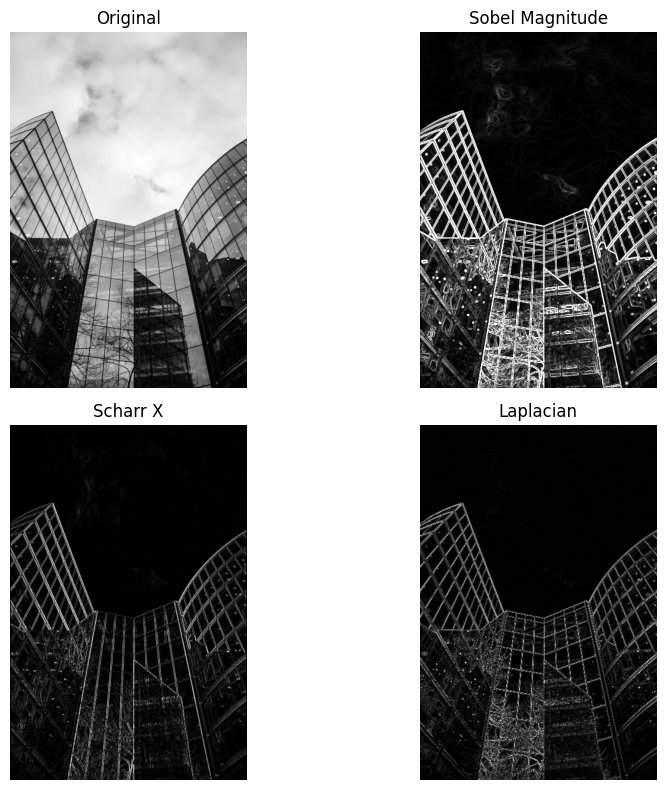

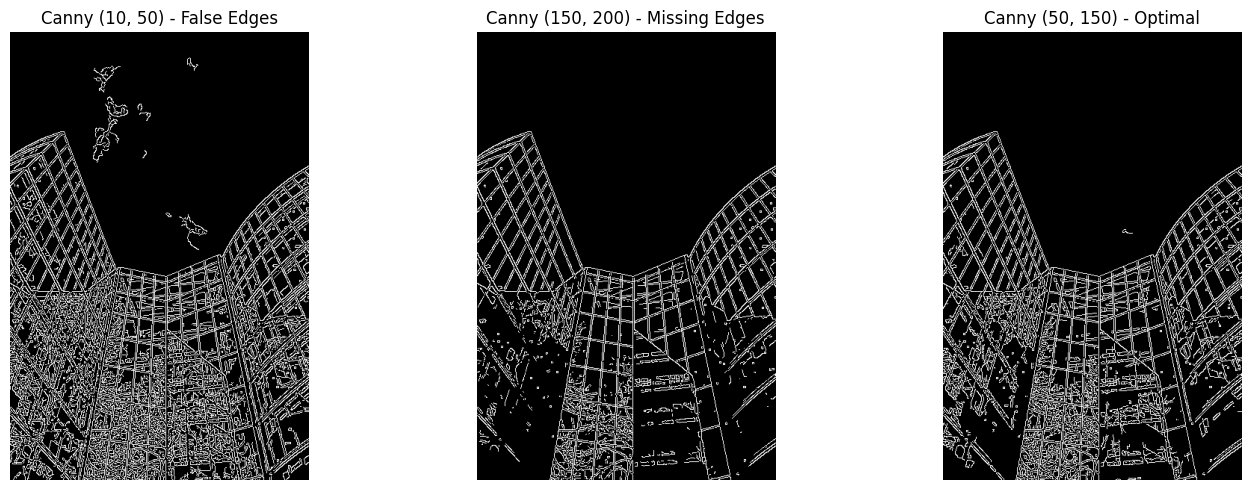

In [7]:
img_build = cv2.cvtColor(load_image('data/images/building.jpg'), cv2.COLOR_RGB2GRAY)
img_build = resize_keep_ratio(img_build, target_width=400)

sobel_x = cv2.Sobel(img_build, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_build, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.uint8(np.clip(cv2.magnitude(sobel_x, sobel_y), 0, 255))
scharr_x = cv2.Scharr(img_build, cv2.CV_64F, 1, 0)
laplacian = cv2.convertScaleAbs(cv2.Laplacian(img_build, cv2.CV_64F))

show_images_grid([img_build, sobel_mag, np.abs(scharr_x), laplacian],
    ['Original', 'Sobel Magnitude', 'Scharr X', 'Laplacian'], 2, 2, cmap='gray', figsize=(10, 8))

canny_low = cv2.Canny(img_build, 10, 50)
canny_high = cv2.Canny(img_build, 150, 200)
canny_opt = cv2.Canny(img_build, 50, 150)

show_images_grid([canny_low, canny_high, canny_opt],
    ['Canny (10, 50) - False Edges', 'Canny (150, 200) - Missing Edges', 'Canny (50, 150) - Optimal'],
    1, 3, cmap='gray', figsize=(15, 5))

## Day 4 — Morphology & Contours
**Topics:** Erosion, Dilation, Opening, Closing, Connected Components

### Understanding Morphology and Object Extraction

This section demonstrates a complete pipeline for cleaning up a noisy image and extracting meaningful geometric properties from the remaining objects.

**1. Morphological Operations (`cv2.morphologyEx`)**
* **Opening (Erosion followed by Dilation):** Using a 5x5 kernel, `cv2.MORPH_OPEN` effectively removes small, random white speckles (salt noise). The initial erosion shrinks away the tiny noise pixels completely, so they cannot be restored during the subsequent dilation, while larger shapes remain largely unaffected.
* **Closing (Dilation followed by Erosion):** Applied with a larger 15x15 kernel, `cv2.MORPH_CLOSE` is used to repair structural defects. The initial dilation expands the white regions enough to bridge the 5-pixel gap in the broken rectangle and fill internal holes. The subsequent erosion shrinks the outer boundaries back to their original dimensions, leaving the internal gaps filled.

**2. Connected Components Analysis (`cv2.connectedComponentsWithStats`)**
* **Concept:** An alternative to `cv2.findContours`, this highly efficient function groups adjacent white pixels into distinct "components" or objects.
* **Mechanism:** 
  * It returns the total number of objects, the label matrix, statistics (bounding box and area), and centroids.
  * **Label 0** is always reserved for the black background, which is why our extraction loop safely starts from index `1`.
  * **Filtering:** By checking `stats[i, cv2.CC_STAT_AREA]`, we can easily filter out any remaining micro-noise (e.g., area < 50 pixels) before extracting the final bounding box coordinates (`x, y, w, h`) and computing the aspect ratio.

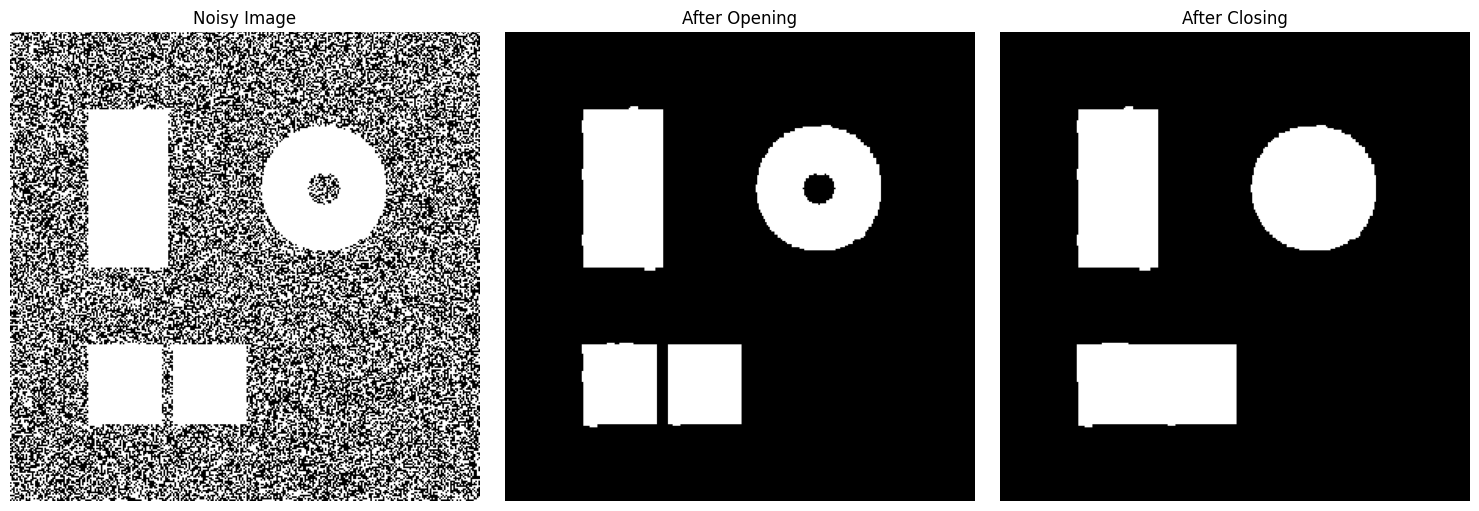

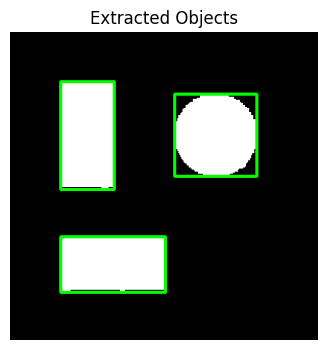

In [ ]:
def generate_synthetic_binary():
    img = np.zeros((300, 300), dtype=np.uint8)
    cv2.rectangle(img, (50, 50), (100, 150), 255, -1)
    cv2.circle(img, (200, 100), 40, 255, -1)
    cv2.circle(img, (200, 100), 10, 0, -1) # Hole
    cv2.rectangle(img, (50, 200), (150, 250), 255, -1)
    cv2.line(img, (100, 190), (100, 260), 0, 5) # Break
    noise = np.random.randint(0, 2, (300, 300), dtype=np.uint8) * 255
    img[noise == 255] = 255
    return img

synth_img = generate_synthetic_binary()
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
opened = cv2.morphologyEx(synth_img, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15)))

show_images_grid([synth_img, opened, closed],
    ['Noisy Image', 'After Opening', 'After Closing'], 1, 3, cmap='gray', figsize=(15, 5))

def extract_objects(mask):
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
    objects = []
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area < 50: continue
        x, y, w, h = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP], stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        objects.append({'bbox': (x, y, w, h), 'area': area, 'centroid': (centroids[i][0], centroids[i][1]), 'aspect_ratio': round(float(w)/h, 2)})
    return objects

objs = extract_objects(closed)
out_img = cv2.cvtColor(closed, cv2.COLOR_GRAY2BGR)
for obj in objs:
    x, y, w, h = obj['bbox']
    cv2.rectangle(out_img, (x, y), (x+w, y+h), (0, 255, 0), 2)
show_image(out_img, "Extracted Objects")

## Day 5 — Hough Lines & Geometry
**Topics:** HoughLinesP, Line representation, Line angle, Intersection, Point-to-line distance

### Understanding Geometry Metrics & The Hough Transform

Detecting edges is only half the battle. In real-world applications (like lane detection, document scanning, or wall-edge analysis), we need to extract mathematical meaning from those edges. 

**1. Robust Geometry Algorithms**
* **Line Angle (`calculate_line_angle`):** Uses `math.atan2` to compute the angle of a detected line segment, normalizing the result to a `[-90, 90]` degree range. This is critical for filtering out horizontal distractor lines when we only care about vertical structures (or vice versa).
* **Point-to-Line Distance (`point_to_line_distance`):** Computes the perpendicular distance from a specific point to a line. Useful for measuring spatial errors or calibrating distances from the camera's optical center.
* **Intersection (`find_intersection`):** Uses determinant-based mathematical formulas to find the exact `(x, y)` intersection of two line segments, while safely handling parallel lines.
* **Unit Testing (`assert`):** Incorporating assertions ensures our core mathematical logic is flawless before deploying it to complex image pipelines.

**2. Probabilistic Hough Transform (`cv2.HoughLinesP`)**
* **Concept:** While the standard Hough Transform detects infinite lines defined by $(\rho, \theta)$, the *Probabilistic* Hough Transform (`HoughLinesP`) is highly optimized and returns the actual endpoints $(x_1, y_1, x_2, y_2)$ of finite line segments.
* **Key Parameters:**
  * `threshold`: The minimum number of intersections (votes) in the Hough accumulator to declare a line.
  * `minLineLength`: Discards any line segments shorter than this value, effectively filtering out noise-induced false lines.
  * `maxLineGap`: The maximum allowable gap between two points on the same line to link them. This is incredibly useful for connecting dashed lane lines or broken edges caused by poor lighting.

Geometry Unit Tests Passed!


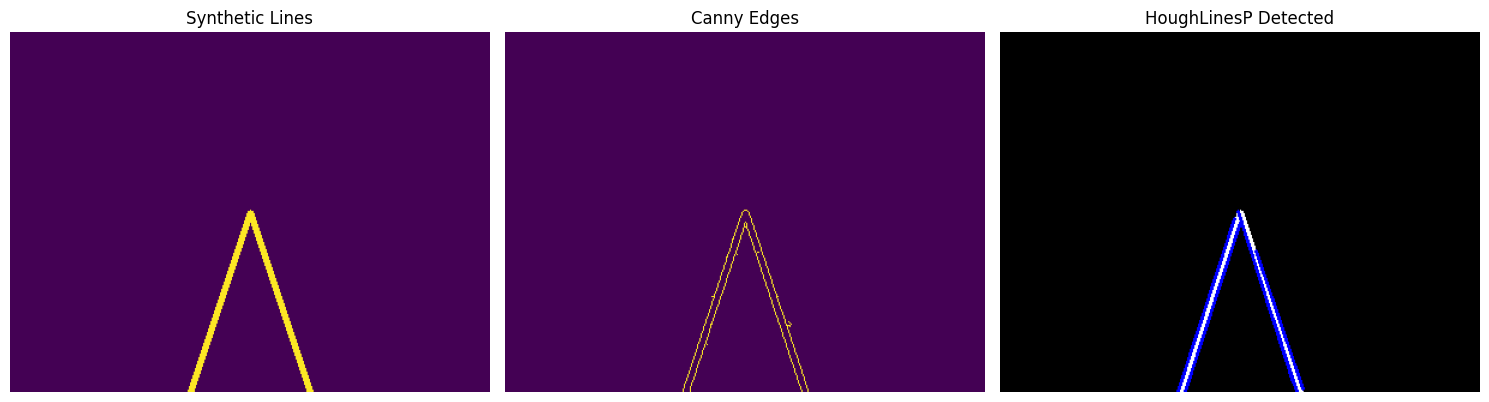

In [13]:
def calculate_line_angle(x1, y1, x2, y2):
    angle = math.degrees(math.atan2(y2 - y1, x2 - x1))
    if angle > 90: angle -= 180
    elif angle < -90: angle += 180
    return angle

def point_to_line_distance(px, py, x1, y1, x2, y2):
    num = abs((x2 - x1) * (y1 - py) - (x1 - px) * (y2 - y1))
    den = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    return num / den if den != 0 else 0

def find_intersection(line1, line2):
    x1, y1, x2, y2 = line1
    x3, y3, x4, y4 = line2
    den = (x1 - x2) * (y3 - y4) - (y1 - y2) * (x3 - x4)
    if den == 0: return None
    px = ((x1*y2 - y1*x2)*(x3 - x4) - (x1 - x2)*(x3*y4 - y3*x4)) / den
    py = ((x1*y2 - y1*x2)*(y3 - y4) - (y1 - y2)*(x3*y4 - y3*x4)) / den
    return (px, py)

assert abs(calculate_line_angle(0, 0, 10, 10) - 45.0) < 1e-5
assert abs(point_to_line_distance(0, 5, 0, 0, 10, 0) - 5.0) < 1e-5
print("Geometry Unit Tests Passed!")

img_lines = np.zeros((300, 400), dtype=np.uint8)
cv2.line(img_lines, (150, 300), (200, 150), 255, 3)
cv2.line(img_lines, (250, 300), (200, 150), 255, 3)

# Add noise and detect edges
edges = cv2.Canny(add_gaussian_noise(img_lines, std=10), 50, 150)

# Detect lines using Hough Transform
lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=50, minLineLength=40, maxLineGap=10)

out_lines = cv2.cvtColor(img_lines, cv2.COLOR_GRAY2BGR)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.flatten()
        cv2.line(out_lines, (x1, y1), (x2, y2), (0, 0, 255), 2)

show_images_grid([img_lines, edges, out_lines], ['Synthetic Lines', 'Canny Edges', 'HoughLinesP Detected'], 1, 3)

## Day 6 — Perspective Transform & Evaluation
**Topics:** Homography, Synthetic Wall Dataset, Line Fitting vs Contours

### Understanding Perspective Transforms and Synthetic Evaluation

To build expert-level computer vision systems, we need the ability to correct geometrical distortions and rigorously evaluate our algorithms against known ground truths.

**1. Perspective Transform (Homography)**
* **Concept:** Allows us to mathematically "warp" an image to simulate a different camera viewpoint, such as generating a flat, top-down "bird's-eye view" from an angled photograph. This is the core technology behind document scanning apps.
* **Mechanism:** 
  * We define 4 Source Points (`src_pts`) on the angled object and 4 corresponding Destination Points (`dst_pts`) forming a perfect rectangle.
  * `cv2.getPerspectiveTransform` calculates a 3x3 Homography matrix representing the planar transformation.
  * `cv2.warpPerspective` applies this transformation matrix to the image pixels.

**2. Synthetic Dataset Generation & Evaluation**
* **The Problem:** How do we know our mathematical line-fitting algorithm is highly accurate? Testing on real images is difficult because we rarely know the *exact* mathematical angle of a wall in a photograph.
* **The Solution:** We generate a synthetic dataset where we define the exact "Ground Truth" (GT) geometry.
* **Creating Challenges:** A perfect edge is too easy to detect. To simulate real-world conditions, the generator intentionally injects variables:
  * Variable background and foreground intensities.
  * Random Gaussian noise (simulating poor camera sensors or shadows).
  * Randomly placed "distractor" lines simulating cracks or cables on the wall, forcing our final pipeline to distinguish between the primary structural edge and random anomalies.

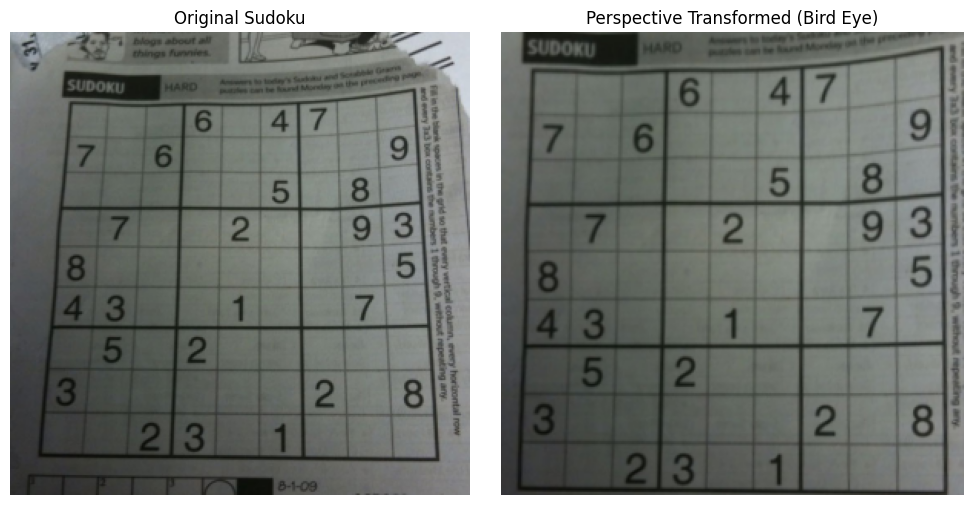

In [10]:
# 1. Perspective Transform (Homography)
img_sudoku = load_image('data/images/sudoku.png')
img_sudoku = resize_keep_ratio(img_sudoku, target_width=300)

# Define source points (corners of the sudoku grid roughly) and destination points
src_pts = np.float32([[23, 27], [275, 30], [8, 280], [290, 280]])
dst_pts = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])

matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)
img_warped = cv2.warpPerspective(img_sudoku, matrix, (300, 300))

show_images_grid([img_sudoku, img_warped], ['Original Sudoku', 'Perspective Transformed (Bird Eye)'], 1, 2, figsize=(10, 5))

# 2. Synthetic Wall Dataset Generator
def generate_wall_test_set(num_samples=10):
    dataset = []
    for _ in range(num_samples):
        img = np.full((300, 300), 150, dtype=np.uint8)
        gt_angle = random.uniform(-30, 30)
        gt_y_center = random.randint(100, 200)
        rad = math.radians(gt_angle)
        dx, dy = math.cos(rad) * 400, math.sin(rad) * 400
        pt1, pt2 = (int(150 - dx), int(gt_y_center - dy)), (int(150 + dx), int(gt_y_center + dy))
        cv2.fillPoly(img, np.array([[pt1, pt2, (pt2[0], 0), (pt1[0], 0)]], dtype=np.int32), 80)
        img = add_gaussian_noise(img, std=random.uniform(5, 20))
        cv2.line(img, (random.randint(0, 300), 0), (random.randint(0, 300), 300), 120, 2) # Distractor
        dataset.append({'image': img, 'gt_angle': gt_angle, 'gt_y_center': gt_y_center})
    return dataset

test_dataset = generate_wall_test_set(10)

## Day 7 — Phase 1 Project (Expert Pipeline)
**Project:** Wall / Reference Line Detection Pipeline

### Understanding the End-to-End Expert Pipeline

This final project combines everything we've learned into a highly robust, production-ready pipeline capable of ignoring noise, shadows, and distractors.

**1. The Auto-Canny Technique**
Hardcoding Canny thresholds is a bad practice for real-world applications where lighting fluctuates. Instead, we calculate the median pixel intensity of the image and dynamically set the lower and upper thresholds based on a percentage deviation from this median. This ensures optimal edge detection regardless of exposure.

**2. Heuristic Filtering**
After `HoughLinesP` extracts all line segments, we apply domain knowledge to filter them. Since we know the reference wall edge is primarily horizontal, we calculate the angle of every segment. Any segment steeper than 45 degrees (like vertical wall cracks, cables, or shadows) is instantly discarded as a distractor.

**3. Robust Line Fitting (`cv2.fitLine`)**
Even after filtering, some inaccurate points may remain. Instead of a simple average, we aggregate all valid endpoints and pass them to `cv2.fitLine`. 
* **The Magic of `DIST_L1`:** Standard Least Squares fitting (L2 norm) is highly sensitive to outliers—a single bad point can tilt the entire line. By using the L1 norm (`cv2.DIST_L1`), the M-estimator algorithm heavily penalizes and effectively ignores outliers, locking onto the true structural edge.

**4. Performance Evaluation**
By running our pipeline against the synthetic ground-truth dataset generated in Day 6, we can quantitatively prove its reliability. We extract the exact line angle and its Y-intercept at the image center, compare them to the hidden ground truth, and calculate the mean absolute error to ensure we meet our >90% success rate target.

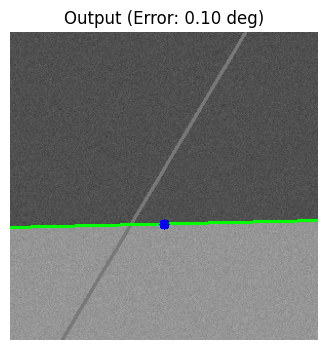

--- EVALUATION REPORT ---\nSuccess Rate: 100.0%\nMean Angle Error: 0.15 deg


In [14]:
def expert_wall_pipeline(image):
    filtered = cv2.bilateralFilter(image, 9, 75, 75)
    v = np.median(filtered)
    edges = cv2.Canny(filtered, int(max(0, (1.0 - 0.33) * v)), int(min(255, (1.0 + 0.33) * v)))
    closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
    
    lines = cv2.HoughLinesP(closed_edges, 1, np.pi/180, 40, minLineLength=60, maxLineGap=20)
    if lines is None: return None
    
    valid_points = []
    for line in lines:
        x1, y1, x2, y2 = line.flatten()
        if abs(calculate_line_angle(x1, y1, x2, y2)) < 45: 
            valid_points.extend([[x1, y1], [x2, y2]])
            
    if not valid_points: return None
    valid_points = np.array(valid_points, dtype=np.int32)
    [vx, vy, x, y] = cv2.fitLine(valid_points, cv2.DIST_L1, 0, 0.01, 0.01)
    
    final_angle = math.degrees(math.atan2(vy[0], vx[0]))
    center_y = (vy[0] / vx[0]) * (150 - x[0]) + y[0]
    return final_angle, center_y, vx[0], vy[0], x[0], y[0]

# --- EVALUATION RUN ---
success_count = 0
angle_errors = []

for i, sample in enumerate(test_dataset):
    img, gt_angle, gt_y = sample['image'], sample['gt_angle'], sample['gt_y_center']
    result = expert_wall_pipeline(img)
    if result:
        success_count += 1
        pred_angle, pred_y, vx, vy, x, y = result
        angle_errors.append(abs(pred_angle - gt_angle))
        
        if success_count == 1:
            annotated = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
            cv2.line(annotated, (int(x - vx*1000), int(y - vy*1000)), (int(x + vx*1000), int(y + vy*1000)), (0, 255, 0), 2)
            cv2.circle(annotated, (150, int(pred_y)), 5, (0,0,255), -1)
            show_image(annotated, f"Output (Error: {abs(pred_angle-gt_angle):.2f} deg)")

print(f"--- EVALUATION REPORT ---\\nSuccess Rate: {success_count / len(test_dataset) * 100:.1f}%\\nMean Angle Error: {np.mean(angle_errors):.2f} deg")

In [ ]:

# cv.ellipse(img,(256,256),(100,50),0,0,180,255,-1)
# pts = np.array([[10,5],[20,30],[70,20],[50,10]], np.int32)
# pts = pts.reshape((-1,1,2))
# cv.polylines(img,[pts],True,(0,255,255))
# font = cv.FONT_HERSHEY_SIMPLEX
# cv.putText(img,'OpenCV',(10,500), font, 4,(255,255,255),2,cv.LINE_AA)
# b,g,r = cv.split(img)
# img = cv.merge((b,g,r))
# dst = cv.addWeighted(img1,0.7,img2,0.3,0)
# rows,cols,channels = img2.shape
# roi = img1[0:rows, 0:cols]

# ## Now create a mask of logo and create its inverse mask also
# img2gray = cv.cvtColor(img2,cv.COLOR_BGR2GRAY)
# ret, mask = cv.threshold(img2gray, 10, 255, cv.THRESH_BINARY)
# mask_inv = cv.bitwise_not(mask)

# ## Now black-out the area of logo in ROI
# img1_bg = cv.bitwise_and(roi,roi,mask = mask_inv)

# ## Take only region of logo from logo image.
# img2_fg = cv.bitwise_and(img2,img2,mask = mask)

# lower_blue = np.array([110,50,50])
# upper_blue = np.array([130,255,255])

# # Threshold the HSV image to get only blue colors
# mask = cv.inRange(hsv, lower_blue, upper_blue)


# cv.warpAffine takes a 2x3 transformation matrix while cv.warpPerspective takes a 3x3 transformation matrix as input.
#  cv.INTER_AREA for shrinking and cv.INTER_CUBIC (slow) & cv.INTER_LINEAR for zooming. By default, the interpolation method cv.INTER_LINEAR is used for all resizing purposes.

# M = np.float32([[1,0,100],[0,1,50]])
# dst = cv.warpAffine(img,M,(cols,rows))

# M = cv.getRotationMatrix2D(((cols-1)/2.0,(rows-1)/2.0),90,1)
# dst = cv.warpAffine(img,M,(cols,rows))

# pts1 = np.float32([[50,50],[200,50],[50,200]])
# pts2 = np.float32([[10,100],[200,50],[100,250]])

# M = cv.getAffineTransform(pts1,pts2)

# dst = cv.warpAffine(img,M,(cols,rows))

# ret,thresh1 = cv.threshold(img,127,255,cv.THRESH_BINARY)
# ret,thresh2 = cv.threshold(img,127,255,cv.THRESH_BINARY_INV)
# ret,thresh3 = cv.threshold(img,127,255,cv.THRESH_TRUNC)
# ret,thresh4 = cv.threshold(img,127,255,cv.THRESH_TOZERO)
# ret,thresh5 = cv.threshold(img,127,255,cv.THRESH_TOZERO_INV)

# kernel = np.ones((5,5),np.float32)/25
# dst = cv.filter2D(img,-1,kernel)

# dst = cv2.boxFilter(src, ddepth, ksize, anchor=(-1, -1), normalize=True, borderType=cv2.BORDER_DEFAULT)

# kernel = np.ones((5,5),np.uint8)
# erosion = cv.erode(img,kernel,iterations = 1)
# dilation = cv.dilate(img,kernel,iterations = 1)
# gradient = cv.morphologyEx(img, cv.MORPH_GRADIENT, kernel)
# tophat = cv.morphologyEx(img, cv.MORPH_TOPHAT, kernel)
# blackhat = cv.morphologyEx(img, cv.MORPH_BLACKHAT, kernel)

# f you want to detect both edges, better option is to keep the output datatype to some higher forms, like cv.CV_16S, cv.CV_64F etc, take its absolute value and then convert back to cv.CV_8U. Below code demonstrates this procedure for a horizontal Sobel filter and difference in results.

# img = cv.imread('messi5.jpg')
# assert img is not None, "file could not be read, check with os.path.exists()"
# lower_reso = cv.pyrDown(higher_reso)
# higher_reso2 = cv.pyrUp(lower_reso)
# Image Blending using Pyramids

# contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
# cv.drawContours(img, contours, -1, (0,255,0), 3)
# cv.drawContours(img, contours, 3, (0,255,0), 3)
# cnt = contours[4]
# cv.drawContours(img, [cnt], 0, (0,255,0), 3)
# cnt = contours[0]
# M = cv.moments(cnt)
# cx = int(M['m10']/M['m00'])
# cy = int(M['m01']/M['m00'])
# area = cv.contourArea(cnt)
# perimeter = cv.arcLength(cnt,True)
# epsilon = 0.1*cv.arcLength(cnt,True)
# approx = cv.approxPolyDP(cnt,epsilon,True)
# hull = cv.convexHull(points[, hull[, clockwise[, returnPoints]]])
# hull = cv.convexHull(cnt)
# k = cv.isContourConvex(cnt)
# x,y,w,h = cv.boundingRect(cnt)
# cv.rectangle(img,(x,y),(x+w,y+h),(0,255,0),2)
# rect = cv.minAreaRect(cnt)
# box = cv.boxPoints(rect)
# box = np.int0(box)
# # cv.drawContours(img,[box],0,(0,0,255),2)
# (x,y),radius = cv.minEnclosingCircle(cnt)
# center = (int(x),int(y))
# radius = int(radius)
# cv.circle(img,center,radius,(0,255,0),2)
# ellipse = cv.fitEllipse(cnt)
# # cv.ellipse(img,ellipse,(0,255,0),2)
# rows,cols = img.shape[:2]
# [vx,vy,x,y] = cv.fitLine(cnt, cv.DIST_L2,0,0.01,0.01)
# lefty = int((-x*vy/vx) + y)
# righty = int(((cols-x)*vy/vx)+y)
# cv.line(img,(cols-1,righty),(0,lefty),(0,255,0),2)
# x,y,w,h = cv.boundingRect(cnt)
# aspect_ratio = float(w)/h
# area = cv.contourArea(cnt)
# x,y,w,h = cv.boundingRect(cnt)
# rect_area = w*h
# # extent = float(area)/rect_area
# area = cv.contourArea(cnt)
# hull = cv.convexHull(cnt)
# hull_area = cv.contourArea(hull)
# solidity = float(area)/hull_area
# area = cv.contourArea(cnt)
# equi_diameter = np.sqrt(4*area/np.pi)
# (x,y),(MA,ma),angle = cv.fitEllipse(cnt)
# mask = np.zeros(imgray.shape,np.uint8)
# cv.drawContours(mask,[cnt],0,255,-1)
# pixelpoints = np.transpose(np.nonzero(mask))
# #pixelpoints = cv.findNonZero(mask)
# min_val, max_val, min_loc, max_loc = cv.minMaxLoc(imgray,mask = mask)

# dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
# dft_shift = np.fft.fftshift(dft)
# magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

# circles = cv.HoughCircles(img,cv.HOUGH_GRADIENT,1,20, param1=50,param2=30,minRadius=0,maxRadius=0)
